In [1]:
import numpy as np
import math 
import random
import scipy.stats as stats

In [2]:
N = 400
T = 2.0
sigma = 0.2
alpha = 0.1
X_init = 0
sim_count = 50000
dt = T/N
up = sigma * math.sqrt(dt)
dn = -up
p = 0.5*(1+alpha/sigma*math.sqrt(dt))
min_val = X_init - N*sigma*math.sqrt(dt)
max_val = X_init + N*sigma*math.sqrt(dt)
bins = np.zeros(N+1)

In [3]:
value = 0
outcomes = np.zeros((sim_count,1))

In [4]:
for sim in np.arange(sim_count):
    X = X_init
    for step in np.arange(N):
        decide = random.random()
        if(decide < p):
            X = X + up
        else:
            X = X + dn
    bin_no = round(N*(X - min_val) / (max_val - min_val))
    bins[bin_no] = bins[bin_no] + 1
    outcomes[sim] = X
    value = value + X

In [5]:
binwidth = (max_val - min_val)/N
xaxis = np.arange(N+1)
value = value / sim_count;

In [6]:
np.mean(outcomes)

0.19966206484838322

In [7]:
np.std(outcomes)

0.28065697899834946

In [8]:
bin_midpoints = np.zeros(N+1)

In [9]:
for i in np.arange(N+1):
    bin_midpoints[i] = min_val + (i-1)*binwidth

In [10]:
bins = bins / sim_count / binwidth

In [11]:
import matplotlib.pyplot as plt
%matplotlib inline
plt.ion()
len(bin_midpoints)
y_pos = np.arange(len(bin_midpoints))


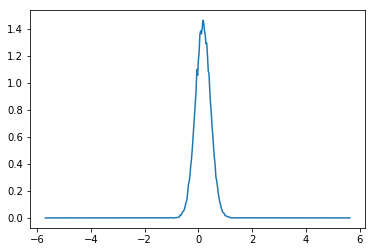

In [12]:
plt.plot(bin_midpoints,bins)

In [14]:
x = np.linspace(min_val,max_val, 1000)
y = stats.norm.pdf(x, alpha*T, sigma*math.sqrt(T))

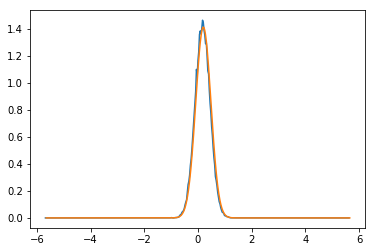

In [15]:
plt.plot(bin_midpoints,bins)
plt.plot(x,y)